In [1]:
# STEP 1: INSPECT CONSUMER ELECTRONICS PURCHASE INTENT DATA

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# PART 1: LOCATE DATASET
# ------------------------------------------------------------

data_folder = (
    Path.home()
    / "Desktop"
    / "supply-chain-portfolio"
    / "kaggle-raw-data"
)

# Locate the purchase-intent CSV
matching_files = [
    file for file in data_folder.iterdir()
    if file.is_file()
    and file.suffix.lower() == ".csv"
    and "purchase" in file.name.lower()
    and "intent" in file.name.lower()
]

assert len(matching_files) == 1, (
    f"Expected one purchase-intent CSV; "
    f"found {len(matching_files)}"
)

intent_file = matching_files[0]

print("===== DATASET INVENTORY =====")

print("File:", intent_file.name)

print(
    "Size (KB):",
    round(intent_file.stat().st_size / 1024, 2)
)


# ------------------------------------------------------------
# PART 2: LOAD DATASET
# ------------------------------------------------------------

# Try UTF-8 first, with an encoding fallback
for encoding in ["utf-8-sig", "cp1252", "latin-1"]:

    try:
        intent_df = pd.read_csv(
            intent_file,
            encoding=encoding,
            low_memory=False
        )

        print("Encoding used:", encoding)
        break

    except UnicodeDecodeError:
        continue


# ------------------------------------------------------------
# PART 3: INSPECT DATASET STRUCTURE
# ------------------------------------------------------------

print("\n===== DATASET STRUCTURE =====")

print("Total rows:", len(intent_df))
print("Total columns:", len(intent_df.columns))

print("\n===== COLUMN NAMES =====")

print(intent_df.columns.tolist())

print("\n===== DATA TYPES =====")

print(intent_df.dtypes)


# ------------------------------------------------------------
# PART 4: DISPLAY SAMPLE RECORDS
# ------------------------------------------------------------

print("\n===== FIRST FIVE RECORDS =====")

display(intent_df.head())


# ------------------------------------------------------------
# PART 5: CHECK DATA QUALITY
# ------------------------------------------------------------

print("\n===== MISSING VALUES =====")

print(intent_df.isna().sum())

print("\n===== DUPLICATE RECORDS =====")

print(intent_df.duplicated().sum())

print("\n===== UNIQUE VALUES PER COLUMN =====")

print(intent_df.nunique(dropna=False))


# ------------------------------------------------------------
# PART 6: DATASET SUMMARY
# ------------------------------------------------------------

print("\n===== DATASET SUMMARY =====")

intent_df.info()

print("\n===== STEP 1 COMPLETE =====")


===== DATASET INVENTORY =====
File: consumer-electronics-customer purchase intent.csv
Size (KB): 467.16
Encoding used: utf-8-sig

===== DATASET STRUCTURE =====
Total rows: 9000
Total columns: 9

===== COLUMN NAMES =====
['ProductID', 'ProductCategory', 'ProductBrand', 'ProductPrice', 'CustomerAge', 'CustomerGender', 'PurchaseFrequency', 'CustomerSatisfaction', 'PurchaseIntent']

===== DATA TYPES =====
ProductID                 int64
ProductCategory             str
ProductBrand                str
ProductPrice            float64
CustomerAge               int64
CustomerGender            int64
PurchaseFrequency         int64
CustomerSatisfaction      int64
PurchaseIntent            int64
dtype: object

===== FIRST FIVE RECORDS =====


,ProductID,ProductCategory,ProductBrand,ProductPrice,CustomerAge,CustomerGender,PurchaseFrequency,CustomerSatisfaction,PurchaseIntent
0,5874,Smartphones,Other Brands,312.949668,18,0,2,1,0
1,5875,Smart Watches,Samsung,980.389404,35,1,7,2,1
2,5876,Tablets,Samsung,2606.718293,63,0,1,5,1
3,5877,Smartphones,Samsung,870.395450,63,1,10,3,1
4,5878,Tablets,Sony,1798.955875,57,0,17,3,0



===== MISSING VALUES =====
ProductID               0
ProductCategory         0
ProductBrand            0
ProductPrice            0
CustomerAge             0
CustomerGender          0
PurchaseFrequency       0
CustomerSatisfaction    0
PurchaseIntent          0
dtype: int64

===== DUPLICATE RECORDS =====
0

===== UNIQUE VALUES PER COLUMN =====
ProductID               9000
ProductCategory            5
ProductBrand               5
ProductPrice            9000
CustomerAge               52
CustomerGender             2
PurchaseFrequency         19
CustomerSatisfaction       5
PurchaseIntent             2
dtype: int64

===== DATASET SUMMARY =====
<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ProductID             9000 non-null   int64  
 1   ProductCategory       9000 non-null   str    
 2   ProductBrand          9000 non-null   str    
 

In [2]:
# STEP 2: ANALYZE PURCHASE INTENT AND CUSTOMER VARIABLES

import pandas as pd

# ------------------------------------------------------------
# PART 1: VALIDATE PURCHASE INTENT TARGET
# ------------------------------------------------------------

print("===== PURCHASE INTENT TARGET VALIDATION =====")

print(
    "Unique target values:",
    sorted(intent_df["PurchaseIntent"].unique())
)

assert set(intent_df["PurchaseIntent"].unique()) == {0, 1}

# ------------------------------------------------------------
# PART 2: PURCHASE INTENT DISTRIBUTION
# ------------------------------------------------------------

intent_summary = (
    intent_df["PurchaseIntent"]
    .value_counts()
    .sort_index()
    .rename_axis("PurchaseIntent")
    .reset_index(name="Records")
)

intent_summary["Percentage"] = (
    intent_summary["Records"]
    / len(intent_df)
    * 100
)

print("\n===== PURCHASE INTENT DISTRIBUTION =====")

display(intent_summary.round(2))


# ------------------------------------------------------------
# PART 3: PURCHASE INTENT BY PRODUCT CATEGORY
# ------------------------------------------------------------

category_intent = (
    intent_df
    .groupby("ProductCategory")
    .agg(
        Records=("PurchaseIntent", "size"),
        Intent_Rate=("PurchaseIntent", "mean"),
        Median_Price=("ProductPrice", "median")
    )
    .reset_index()
)

category_intent["Intent_Rate_Pct"] = (
    category_intent["Intent_Rate"] * 100
)

category_intent = category_intent.sort_values(
    "Intent_Rate_Pct",
    ascending=False
)

print("\n===== PURCHASE INTENT BY CATEGORY =====")

display(
    category_intent[
        [
            "ProductCategory",
            "Records",
            "Intent_Rate_Pct",
            "Median_Price"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 4: PURCHASE INTENT BY PRODUCT BRAND
# ------------------------------------------------------------

brand_intent = (
    intent_df
    .groupby("ProductBrand")
    .agg(
        Records=("PurchaseIntent", "size"),
        Intent_Rate=("PurchaseIntent", "mean")
    )
    .reset_index()
)

brand_intent["Intent_Rate_Pct"] = (
    brand_intent["Intent_Rate"] * 100
)

brand_intent = brand_intent.sort_values(
    "Intent_Rate_Pct",
    ascending=False
)

print("\n===== PURCHASE INTENT BY BRAND =====")

display(
    brand_intent[
        ["ProductBrand", "Records", "Intent_Rate_Pct"]
    ].round(2)
)


# ------------------------------------------------------------
# PART 5: COMPARE CUSTOMER CHARACTERISTICS
# ------------------------------------------------------------

customer_comparison = (
    intent_df
    .groupby("PurchaseIntent")
    [
        [
            "CustomerAge",
            "ProductPrice",
            "PurchaseFrequency",
            "CustomerSatisfaction"
        ]
    ]
    .mean()
    .round(2)
)

print("\n===== CUSTOMER CHARACTERISTICS BY INTENT =====")

display(customer_comparison)


# ------------------------------------------------------------
# PART 6: IDENTIFIER VALIDATION
# ------------------------------------------------------------

print("\n===== PRODUCT ID VALIDATION =====")

print(
    "Unique Product IDs:",
    intent_df["ProductID"].nunique()
)

print(
    "Total records:",
    len(intent_df)
)

print("\n===== STEP 2 COMPLETE =====")


===== PURCHASE INTENT TARGET VALIDATION =====
Unique target values: [np.int64(0), np.int64(1)]

===== PURCHASE INTENT DISTRIBUTION =====


,PurchaseIntent,Records,Percentage
0,0,3902,43.36
1,1,5098,56.64



===== PURCHASE INTENT BY CATEGORY =====


,ProductCategory,Records,Intent_Rate_Pct,Median_Price
3,Smartphones,1841,58.28,1464.31
2,Smart Watches,1810,58.12,1536.40
4,Tablets,1769,56.08,1521.79
0,Headphones,1738,55.98,1567.39
1,Laptops,1842,54.72,1503.70



===== PURCHASE INTENT BY BRAND =====


,ProductBrand,Records,Intent_Rate_Pct
0,Apple,1760,58.69
1,HP,1820,57.36
2,Other Brands,1776,56.64
4,Sony,1790,56.20
3,Samsung,1854,54.42



===== CUSTOMER CHARACTERISTICS BY INTENT =====


,CustomerAge,ProductPrice,PurchaseFrequency,CustomerSatisfaction
PurchaseIntent,,,,
0,38.36,1544.04,10.06,2.37
1,47.16,1514.72,10.05,3.48



===== PRODUCT ID VALIDATION =====
Unique Product IDs: 9000
Total records: 9000

===== STEP 2 COMPLETE =====


In [3]:
# STEP 3: INVESTIGATE PURCHASE INTENT DRIVERS

import pandas as pd

# ------------------------------------------------------------
# PART 1: PURCHASE INTENT BY CUSTOMER SATISFACTION
# ------------------------------------------------------------

satisfaction_analysis = (
    intent_df
    .groupby("CustomerSatisfaction")
    .agg(
        Records=("PurchaseIntent", "size"),
        Positive_Intent=("PurchaseIntent", "sum"),
        Intent_Rate=("PurchaseIntent", "mean")
    )
    .reset_index()
)

satisfaction_analysis["Intent_Rate_Pct"] = (
    satisfaction_analysis["Intent_Rate"] * 100
)

print("===== PURCHASE INTENT BY SATISFACTION =====")

display(
    satisfaction_analysis[
        [
            "CustomerSatisfaction",
            "Records",
            "Positive_Intent",
            "Intent_Rate_Pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 2: PURCHASE INTENT BY CUSTOMER AGE
# ------------------------------------------------------------

age_analysis = intent_df.copy()

# Divide customers into five approximately equal groups
age_analysis["Age_Group"] = pd.qcut(
    age_analysis["CustomerAge"],
    q=5,
    duplicates="drop"
)

age_summary = (
    age_analysis
    .groupby("Age_Group", observed=True)
    .agg(
        Records=("PurchaseIntent", "size"),
        Intent_Rate=("PurchaseIntent", "mean"),
        Average_Age=("CustomerAge", "mean")
    )
    .reset_index()
)

age_summary["Intent_Rate_Pct"] = (
    age_summary["Intent_Rate"] * 100
)

print("\n===== PURCHASE INTENT BY AGE GROUP =====")

display(
    age_summary[
        [
            "Age_Group",
            "Records",
            "Average_Age",
            "Intent_Rate_Pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 3: PURCHASE INTENT BY PURCHASE FREQUENCY
# ------------------------------------------------------------

frequency_analysis = (
    intent_df
    .groupby("PurchaseFrequency")
    .agg(
        Records=("PurchaseIntent", "size"),
        Intent_Rate=("PurchaseIntent", "mean")
    )
    .reset_index()
    .sort_values("PurchaseFrequency")
)

frequency_analysis["Intent_Rate_Pct"] = (
    frequency_analysis["Intent_Rate"] * 100
)

print("\n===== PURCHASE INTENT BY FREQUENCY =====")

display(
    frequency_analysis[
        [
            "PurchaseFrequency",
            "Records",
            "Intent_Rate_Pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 4: COMPARE NUMERICAL VARIABLES WITH INTENT
# ------------------------------------------------------------

numeric_columns = [
    "ProductPrice",
    "CustomerAge",
    "PurchaseFrequency",
    "CustomerSatisfaction",
    "PurchaseIntent"
]

correlation_matrix = (
    intent_df[numeric_columns].corr()
)

intent_correlations = (
    correlation_matrix["PurchaseIntent"]
    .drop("PurchaseIntent")
    .sort_values(ascending=False)
)

print("\n===== CORRELATION WITH PURCHASE INTENT =====")

display(
    intent_correlations
    .to_frame("Correlation")
    .round(3)
)

print("\n===== STEP 3 COMPLETE =====")


===== PURCHASE INTENT BY SATISFACTION =====


,CustomerSatisfaction,Records,Positive_Intent,Intent_Rate_Pct
0,1,1775,684,38.54
1,2,1814,706,38.92
2,3,1848,696,37.66
3,4,1798,1519,84.48
4,5,1765,1493,84.59



===== PURCHASE INTENT BY AGE GROUP =====


,Age_Group,Records,Average_Age,Intent_Rate_Pct
0,"(17.999, 28.0]",1938,22.93,24.20
1,"(28.0, 38.0]",1725,33.38,57.80
2,"(38.0, 49.0]",1859,43.90,68.59
3,"(49.0, 59.0]",1781,54.50,68.33
4,"(59.0, 69.0]",1697,64.48,67.18



===== PURCHASE INTENT BY FREQUENCY =====


,PurchaseFrequency,Records,Intent_Rate_Pct
0,1,439,58.54
1,2,455,56.26
2,3,488,56.35
3,4,481,59.46
4,5,478,53.97
5,6,452,57.74
6,7,506,56.72
7,8,466,55.15
8,9,463,56.80
9,10,477,54.09



===== CORRELATION WITH PURCHASE INTENT =====


,Correlation
CustomerSatisfaction,0.391
CustomerAge,0.290
PurchaseFrequency,-0.001
ProductPrice,-0.018



===== STEP 3 COMPLETE =====


In [4]:
# STEP 4: PREPARE PURCHASE INTENT CLASSIFICATION DATA

import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# PART 1: IDENTIFY TARGET VARIABLE
# ------------------------------------------------------------

target_column = "PurchaseIntent"

# Binary classification target
y = intent_df[target_column].astype(int)

assert set(y.unique()) == {0, 1}

print("===== CLASSIFICATION TARGET =====")

print("Total records:", len(y))
print("Positive intent rate:", round(y.mean() * 100, 2), "%")


# ------------------------------------------------------------
# PART 2: DEFINE FEATURE GROUPS
# ------------------------------------------------------------

# Basic product information
product_features = [
    "ProductCategory",
    "ProductBrand",
    "ProductPrice"
]

# Add potentially available customer information
customer_features = product_features + [
    "CustomerAge",
    "PurchaseFrequency"
]

# Exploratory features with potential leakage risk
satisfaction_features = customer_features + [
    "CustomerSatisfaction"
]

feature_groups = {
    "Product_Context": product_features,
    "Customer_Enriched": customer_features,
    "Satisfaction_Sensitivity": satisfaction_features
}

print("\n===== FEATURE GROUPS =====")

for group_name, features in feature_groups.items():
    print(f"{group_name}: {features}")


# ------------------------------------------------------------
# PART 3: CREATE TRAIN / TEST SPLIT
# ------------------------------------------------------------

# No date column exists, so use a stratified random split.
# Fix the random state for reproducibility.

train_idx, test_idx = train_test_split(
    intent_df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

print("\n===== TRAIN / TEST SPLIT =====")

print("Training records:", len(y_train))
print("Testing records:", len(y_test))

print(
    "Training positive rate:",
    round(y_train.mean() * 100, 2), "%"
)

print(
    "Testing positive rate:",
    round(y_test.mean() * 100, 2), "%"
)


# ------------------------------------------------------------
# PART 4: PREPARE FEATURES FOR EACH EXPERIMENT
# ------------------------------------------------------------

X_train_sets = {}
X_test_sets = {}

for group_name, features in feature_groups.items():

    X_train_sets[group_name] = (
        intent_df.loc[train_idx, features].copy()
    )

    X_test_sets[group_name] = (
        intent_df.loc[test_idx, features].copy()
    )

    print(f"\n===== {group_name} =====")

    print(
        "Training shape:",
        X_train_sets[group_name].shape
    )

    print(
        "Testing shape:",
        X_test_sets[group_name].shape
    )


# ------------------------------------------------------------
# PART 5: VALIDATE DATA SEPARATION
# ------------------------------------------------------------

assert len(set(train_idx).intersection(set(test_idx))) == 0

assert len(train_idx) + len(test_idx) == len(intent_df)

print("\n===== DATA VALIDATION =====")

print("Training and testing indices do not overlap.")
print("All 9,000 records accounted for.")

print("\n===== STEP 4 COMPLETE =====")


===== CLASSIFICATION TARGET =====
Total records: 9000
Positive intent rate: 56.64 %

===== FEATURE GROUPS =====
Product_Context: ['ProductCategory', 'ProductBrand', 'ProductPrice']
Customer_Enriched: ['ProductCategory', 'ProductBrand', 'ProductPrice', 'CustomerAge', 'PurchaseFrequency']
Satisfaction_Sensitivity: ['ProductCategory', 'ProductBrand', 'ProductPrice', 'CustomerAge', 'PurchaseFrequency', 'CustomerSatisfaction']

===== TRAIN / TEST SPLIT =====
Training records: 7200
Testing records: 1800
Training positive rate: 56.64 %
Testing positive rate: 56.67 %

===== Product_Context =====
Training shape: (7200, 3)
Testing shape: (1800, 3)

===== Customer_Enriched =====
Training shape: (7200, 5)
Testing shape: (1800, 5)

===== Satisfaction_Sensitivity =====
Training shape: (7200, 6)
Testing shape: (1800, 6)

===== DATA VALIDATION =====
Training and testing indices do not overlap.
All 9,000 records accounted for.

===== STEP 4 COMPLETE =====


In [5]:
# STEP 5: TRAIN AND EVALUATE CLASSIFICATION MODELS

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# PART 1: DEFINE FEATURE TYPES
# ------------------------------------------------------------

categorical_columns = [
    "ProductCategory",
    "ProductBrand"
]

numerical_columns = [
    "ProductPrice",
    "CustomerAge",
    "PurchaseFrequency",
    "CustomerSatisfaction"
]

# ------------------------------------------------------------
# PART 2: CREATE PREPROCESSING PIPELINE
# ------------------------------------------------------------

def create_pipeline(features, classifier):

    categorical_features = [
        col for col in features
        if col in categorical_columns
    ]

    numerical_features = [
        col for col in features
        if col in numerical_columns
    ]

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer([
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        ),
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        )
    ])

    return Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])


# ------------------------------------------------------------
# PART 3: CREATE MAJORITY-CLASS BASELINE
# ------------------------------------------------------------

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    X_train_sets["Product_Context"],
    y_train
)

baseline_predictions = baseline.predict(
    X_test_sets["Product_Context"]
)

baseline_probabilities = baseline.predict_proba(
    X_test_sets["Product_Context"]
)[:, 1]

# Store evaluation results
evaluation_results = []

evaluation_results.append({
    "Model": "Majority Class",
    "Feature_Group": "Baseline",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test, baseline_probabilities
    )
})

# ------------------------------------------------------------
# PART 4: TRAIN LOGISTIC REGRESSION AND RANDOM FOREST
# ------------------------------------------------------------

trained_models = {}

for group_name, features in feature_groups.items():

    X_train = X_train_sets[group_name]
    X_test = X_test_sets[group_name]

    classifiers = {
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        )
    }

    for model_name, classifier in classifiers.items():

        # Create model with preprocessing
        pipeline = create_pipeline(
            features,
            classifier
        )

        # Train only on training records
        pipeline.fit(X_train, y_train)

        # Predict on the held-out test set
        predictions = pipeline.predict(X_test)

        probabilities = pipeline.predict_proba(
            X_test
        )[:, 1]

        # Calculate performance metrics
        evaluation_results.append({
            "Model": model_name,
            "Feature_Group": group_name,
            "Accuracy": accuracy_score(
                y_test, predictions
            ),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                y_test, probabilities
            )
        })

        # Save fitted model for later analysis
        trained_models[
            (group_name, model_name)
        ] = pipeline

        print(
            f"Trained: {model_name} | {group_name}"
        )


# ------------------------------------------------------------
# PART 5: CREATE MODEL PERFORMANCE LEADERBOARD
# ------------------------------------------------------------

classification_results = pd.DataFrame(
    evaluation_results
)

classification_results = (
    classification_results
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n===== PURCHASE INTENT MODEL LEADERBOARD =====")

display(
    classification_results.round(3)
)


# ------------------------------------------------------------
# PART 6: COMPARE MODELS WITHOUT SATISFACTION
# ------------------------------------------------------------

operational_comparison = (
    classification_results[
        classification_results["Feature_Group"]
        != "Satisfaction_Sensitivity"
    ]
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
)

print("\n===== MODELS EXCLUDING SATISFACTION =====")

display(
    operational_comparison.round(3)
)

print("\n===== STEP 5 COMPLETE =====")


Trained: Logistic Regression | Product_Context
Trained: Random Forest | Product_Context
Trained: Logistic Regression | Customer_Enriched
Trained: Random Forest | Customer_Enriched
Trained: Logistic Regression | Satisfaction_Sensitivity
Trained: Random Forest | Satisfaction_Sensitivity

===== PURCHASE INTENT MODEL LEADERBOARD =====


,Model,Feature_Group,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,Satisfaction_Sensitivity,0.687,0.724,0.725,0.724,0.800
1,Logistic Regression,Satisfaction_Sensitivity,0.694,0.721,0.752,0.736,0.779
2,Logistic Regression,Customer_Enriched,0.658,0.677,0.758,0.715,0.665
3,Random Forest,Customer_Enriched,0.682,0.667,0.875,0.757,0.662
4,Random Forest,Product_Context,0.541,0.577,0.706,0.635,0.534
5,Logistic Regression,Product_Context,0.567,0.567,1.000,0.723,0.513
6,Majority Class,Baseline,0.567,0.567,1.000,0.723,0.500



===== MODELS EXCLUDING SATISFACTION =====


,Model,Feature_Group,Accuracy,Precision,Recall,F1,ROC_AUC
2,Logistic Regression,Customer_Enriched,0.658,0.677,0.758,0.715,0.665
3,Random Forest,Customer_Enriched,0.682,0.667,0.875,0.757,0.662
4,Random Forest,Product_Context,0.541,0.577,0.706,0.635,0.534
5,Logistic Regression,Product_Context,0.567,0.567,1.000,0.723,0.513
6,Majority Class,Baseline,0.567,0.567,1.000,0.723,0.500



===== STEP 5 COMPLETE =====


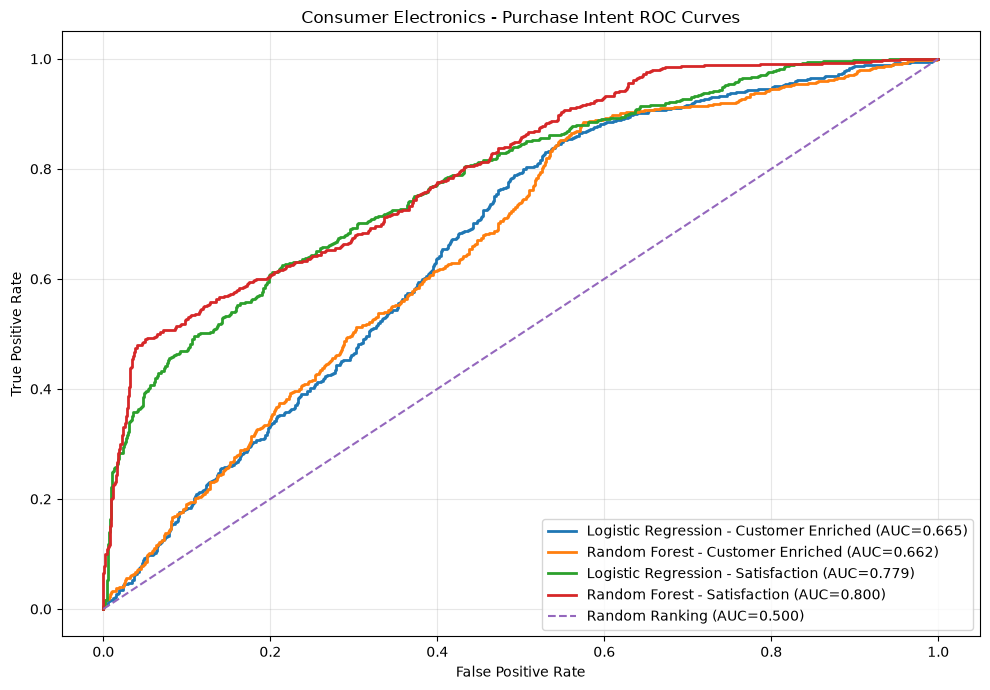

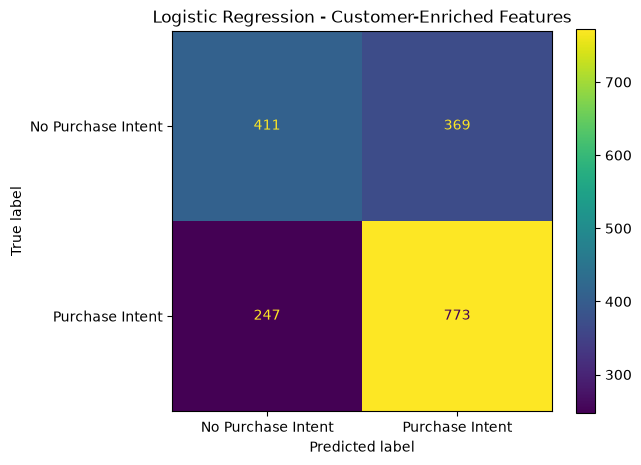

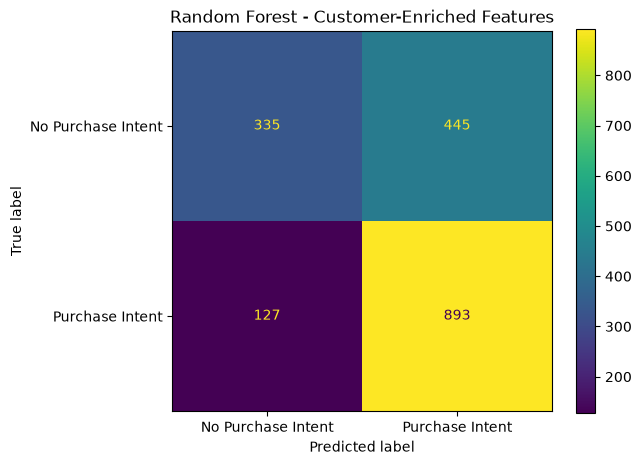


===== LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

           0       0.62      0.53      0.57       780
           1       0.68      0.76      0.72      1020

    accuracy                           0.66      1800
   macro avg       0.65      0.64      0.64      1800
weighted avg       0.65      0.66      0.65      1800


===== RANDOM FOREST =====
              precision    recall  f1-score   support

           0       0.73      0.43      0.54       780
           1       0.67      0.88      0.76      1020

    accuracy                           0.68      1800
   macro avg       0.70      0.65      0.65      1800
weighted avg       0.69      0.68      0.66      1800


===== STEP 6 COMPLETE =====


In [6]:
# STEP 6: VISUALIZE CLASSIFICATION MODEL PERFORMANCE

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# ------------------------------------------------------------
# PART 1: SELECT MODELS FOR VISUAL COMPARISON
# ------------------------------------------------------------

models_to_compare = {
    "Logistic Regression - Customer Enriched": (
        "Customer_Enriched",
        "Logistic Regression"
    ),

    "Random Forest - Customer Enriched": (
        "Customer_Enriched",
        "Random Forest"
    ),

    "Logistic Regression - Satisfaction": (
        "Satisfaction_Sensitivity",
        "Logistic Regression"
    ),

    "Random Forest - Satisfaction": (
        "Satisfaction_Sensitivity",
        "Random Forest"
    )
}


# ------------------------------------------------------------
# PART 2: VISUALIZE ROC CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

for label, (feature_group, model_name) in (
    models_to_compare.items()
):

    model = trained_models[
        (feature_group, model_name)
    ]

    X_test = X_test_sets[feature_group]

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{label} (AUC={auc_score:.3f})"
    )

# Random ranking reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Ranking (AUC=0.500)"
)

plt.title(
    "Consumer Electronics - Purchase Intent ROC Curves"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# PART 3: VISUALIZE CONFUSION MATRICES
# ------------------------------------------------------------

# Focus on models that exclude satisfaction
models_for_confusion = {
    "Logistic Regression": (
        "Customer_Enriched",
        "Logistic Regression"
    ),

    "Random Forest": (
        "Customer_Enriched",
        "Random Forest"
    )
}

for label, (feature_group, model_name) in (
    models_for_confusion.items()
):

    model = trained_models[
        (feature_group, model_name)
    ]

    predictions = model.predict(
        X_test_sets[feature_group]
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No Purchase Intent",
            "Purchase Intent"
        ]
    )

    display_matrix.plot(
        values_format="d"
    )

    plt.title(
        f"{label} - Customer-Enriched Features"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# PART 4: PRINT CLASSIFICATION REPORTS
# ------------------------------------------------------------

for label, (feature_group, model_name) in (
    models_for_confusion.items()
):

    model = trained_models[
        (feature_group, model_name)
    ]

    predictions = model.predict(
        X_test_sets[feature_group]
    )

    print(f"\n===== {label.upper()} =====")

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

print("\n===== STEP 6 COMPLETE =====")


===== MODEL LEADERBOARD EXPORTED =====
Saved: data/processed/purchase_intent_model_leaderboard.csv
Models: 7

===== CONFUSION MATRIX SUMMARY =====


,Model,True_Negatives,False_Positives,False_Negatives,True_Positives
0,Logistic Regression,411,369,247,773
1,Random Forest,335,445,127,893


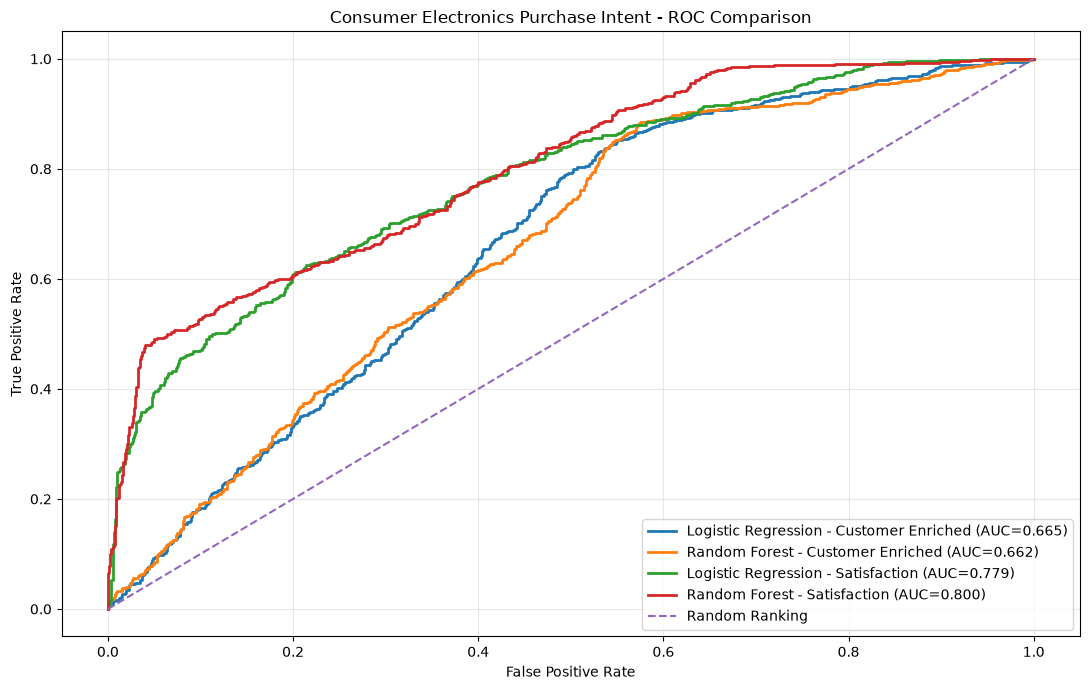

Saved: reports/figures/purchase_intent_roc_curves.png


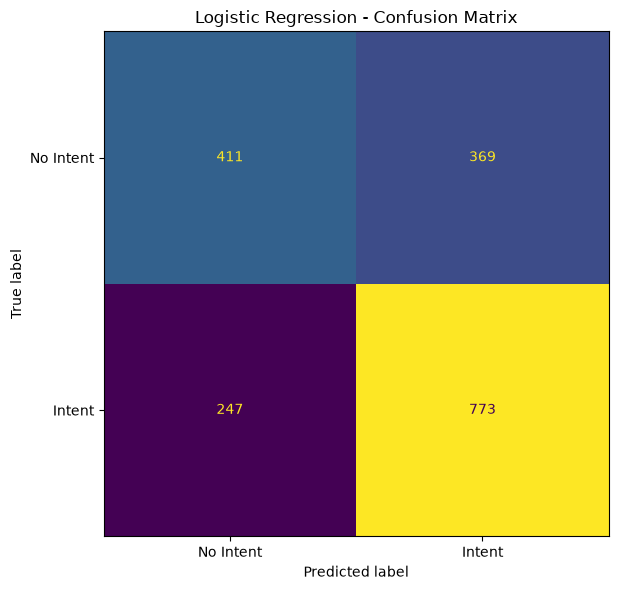

Saved: reports/figures/purchase_intent_logistic_regression_confusion.png


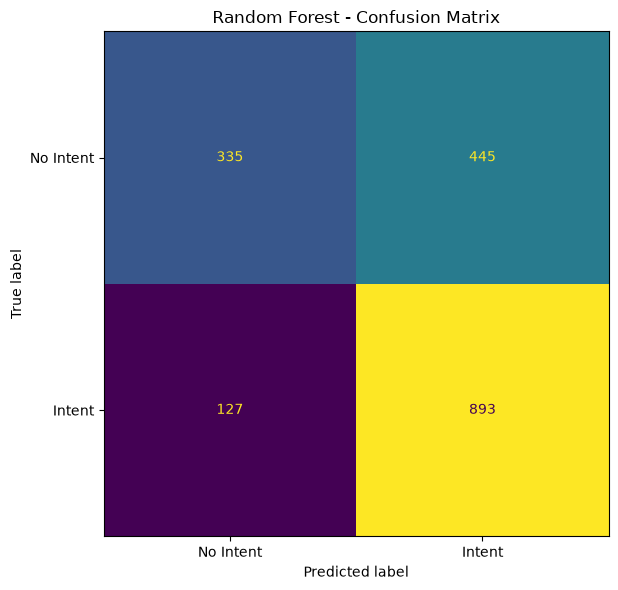

Saved: reports/figures/purchase_intent_random_forest_confusion.png

===== EXPORT VALIDATION =====
Verified: purchase_intent_model_leaderboard.csv
Verified: purchase_intent_confusion_summary.csv
Verified: purchase_intent_roc_curves.png
Verified: purchase_intent_logistic_regression_confusion.png
Verified: purchase_intent_random_forest_confusion.png

===== STEP 7 COMPLETE =====


In [7]:
# STEP 7: EXPORT PURCHASE INTENT MODEL RESULTS

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# PART 1: CREATE OUTPUT FOLDERS
# ------------------------------------------------------------

output_dir = Path("data/processed")
figures_dir = Path("reports/figures")

output_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PART 2: EXPORT MODEL LEADERBOARD
# ------------------------------------------------------------

leaderboard_path = (
    output_dir / "purchase_intent_model_leaderboard.csv"
)

classification_results.to_csv(
    leaderboard_path,
    index=False
)

print("===== MODEL LEADERBOARD EXPORTED =====")
print("Saved:", leaderboard_path)
print("Models:", len(classification_results))


# ------------------------------------------------------------
# PART 3: EXPORT CONFUSION MATRIX SUMMARY
# ------------------------------------------------------------

confusion_records = []

for label, (feature_group, model_name) in (
    models_for_confusion.items()
):

    model = trained_models[
        (feature_group, model_name)
    ]

    predictions = model.predict(
        X_test_sets[feature_group]
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    confusion_records.append({
        "Model": label,
        "True_Negatives": tn,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp
    })

confusion_summary = pd.DataFrame(confusion_records)

confusion_path = (
    output_dir / "purchase_intent_confusion_summary.csv"
)

confusion_summary.to_csv(
    confusion_path,
    index=False
)

print("\n===== CONFUSION MATRIX SUMMARY =====")
display(confusion_summary)


# ------------------------------------------------------------
# PART 4: SAVE ROC COMPARISON FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

for label, (feature_group, model_name) in (
    models_to_compare.items()
):

    model = trained_models[
        (feature_group, model_name)
    ]

    probabilities = model.predict_proba(
        X_test_sets[feature_group]
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{label} (AUC={auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Ranking"
)

ax.set_title("Consumer Electronics Purchase Intent - ROC Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

fig.tight_layout()

roc_path = figures_dir / "purchase_intent_roc_curves.png"

fig.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", roc_path)


# ------------------------------------------------------------
# PART 5: SAVE CONFUSION MATRIX FIGURES
# ------------------------------------------------------------

for label, (feature_group, model_name) in (
    models_for_confusion.items()
):

    model = trained_models[
        (feature_group, model_name)
    ]

    predictions = model.predict(
        X_test_sets[feature_group]
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Intent", "Intent"]
    )

    disp.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{label} - Confusion Matrix")

    fig.tight_layout()

    filename = (
        "purchase_intent_"
        + model_name.lower().replace(" ", "_")
        + "_confusion.png"
    )

    figure_path = figures_dir / filename

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", figure_path)


# ------------------------------------------------------------
# PART 6: VALIDATE EXPORTED FILES
# ------------------------------------------------------------

exported_files = [
    leaderboard_path,
    confusion_path,
    roc_path,
    figures_dir / "purchase_intent_logistic_regression_confusion.png",
    figures_dir / "purchase_intent_random_forest_confusion.png"
]

print("\n===== EXPORT VALIDATION =====")

for file_path in exported_files:

    assert file_path.is_file()
    assert file_path.stat().st_size > 0

    print("Verified:", file_path.name)

print("\n===== STEP 7 COMPLETE =====")



# Consumer Electronics Purchase Intent — Findings and Methodology

## 1. Research Objective

Investigate how product attributes and customer
characteristics relate to consumer electronics purchase
intent.

Evaluate supervised machine-learning models to determine
whether available features can distinguish positive
from negative purchase intent.

This analysis supports the broader Hardware Demand-Sensing
& Launch Readiness Planner portfolio project.

## 2. Dataset Overview

Source: Consumer Electronics Customer Purchase Intent
(Kaggle)

Dataset characteristics:
- 9,000 observations
- 9 variables
- 0 missing values
- 0 duplicate records
- Binary target: PurchaseIntent (0 or 1)

Target distribution:
- Positive intent: 5,098 records (56.64%)
- Negative intent: 3,902 records (43.36%)

The dataset does not include transaction dates or
verified completed purchase outcomes.

## 3. Exploratory Data Analysis

Analyzed purchase-intent rates across:
- Product categories
- Product brands
- Customer age groups
- Customer satisfaction levels
- Purchase frequency

Key findings:

Customer satisfaction demonstrated a correlation
of approximately 0.391 with purchase intent.

Customer age demonstrated a correlation of
approximately 0.290.

Purchase frequency and product price showed
minimal overall linear correlations with intent.

These results describe statistical associations,
not causal effects.

## 4. Feature Engineering and Data Preparation

Excluded ProductID because each record has a unique
identifier and its predictive meaning is unverified.

Created three experimental feature sets:

1. Product Context
   - Product category
   - Product brand
   - Product price

2. Customer Enriched
   - Product context features
   - Customer age
   - Purchase frequency

3. Satisfaction Sensitivity
   - Customer-enriched features
   - Customer satisfaction

Used an 80/20 stratified train-test split:

- Training observations: 7,200
- Testing observations: 1,800

Applied categorical encoding, numerical scaling,
and missing-value imputation through Scikit-learn
pipelines fitted on training data.

## 5. Machine Learning Methodology

Compared seven classification configurations:

- Majority-class baseline
- Logistic Regression across three feature groups
- Random Forest across three feature groups

Evaluation metrics included:
- Accuracy
- Precision
- Recall
- F1 score
- ROC-AUC

## 6. Model Performance

Majority-class baseline:
- Accuracy: 56.7%
- ROC-AUC: 0.500

Customer-enriched Logistic Regression:
- Accuracy: 65.8%
- ROC-AUC: 0.665

Customer-enriched Random Forest:
- Accuracy: 68.2%
- ROC-AUC: 0.662
- Positive-class recall: 87.5%

Satisfaction-sensitivity Random Forest:
- Accuracy: 68.7%
- ROC-AUC: 0.800

Satisfaction-sensitivity Logistic Regression:
- Accuracy: 69.4%
- ROC-AUC: 0.779

Models incorporating customer characteristics
generally outperformed product-only configurations.

Satisfaction-enhanced models demonstrated stronger
discrimination but require additional leakage review.

## 7. Confusion Matrix Analysis

Customer-enriched Logistic Regression:
- True negatives: 411
- False positives: 369
- False negatives: 247
- True positives: 773

Customer-enriched Random Forest:
- True negatives: 335
- False positives: 445
- False negatives: 127
- True positives: 893

Random Forest identified more positive-intent records
but also generated more false positives.

Model choice should reflect the business consequences
of false-positive and false-negative predictions.

## 8. Business Implications

Purchase-intent classification could support:
- Customer-segment analysis
- Product preference research
- Purchase-propensity investigation
- Demand-signal research
- Marketing and planning scenario analysis

Intent probabilities are not equivalent to realized
sales or forecasted unit demand.

Additional calibration and conversion evidence would
be necessary before using predicted intent in
inventory-planning decisions.

## 9. Analytical Limitations

- No chronological information is available.
- Purchase intent is not a completed purchase.
- Customer satisfaction may introduce target leakage.
- Customer age requires fairness and appropriate-use review.
- ProductID has no established predictive meaning.
- Model comparisons used one held-out test set.
- Final model selection requires stronger validation,
  including cross-validation and fresh evaluation data.
- The dataset may contain synthetic or simplified
  relationships; provenance requires verification.
- No operational or financial improvement has
  been demonstrated.

## 10. Next Research Phase

The next project phase will evaluate how findings from
four independent Kaggle sources can contribute to a
coherent demand-sensing and planning framework.

Planned work:
- Strengthen forecast and classification validation
- Evaluate external market signals
- Develop inventory and stockout-risk scenarios
- Model hypothetical launch readiness
- Create Power BI dashboards
- Build a documented portfolio case study

Independent datasets will not be treated as directly
linked customer or transaction records without
verified common identifiers.
